<a href="https://colab.research.google.com/github/SeekerKids/Portofolio/blob/main/Case_Study_3_Dynamic_Pricing_menggunakan_Clustering_dan_Linear_Regression_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Study 3: Customer Dynamic Pricing menggunakan Clustering dan Linear Regression**


# Input Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


+-------------------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
| Column Name             |   Missing Values | Data Type   |   Unique Values | Sample Values                                                      |
+=========================+==================+=============+=================+====================================================================+
| Number_of_Riders        |                0 | int64       |              81 | [90 58 42 89 78 59 93 62 79 86]                                    |
+-------------------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
| Number_of_Drivers       |                0 | int64       |              79 | [45 39 31 28 22 35 43 14  6 17]                                    |
+-------------------------+------------------+-------------+-----------------+----------------------------------

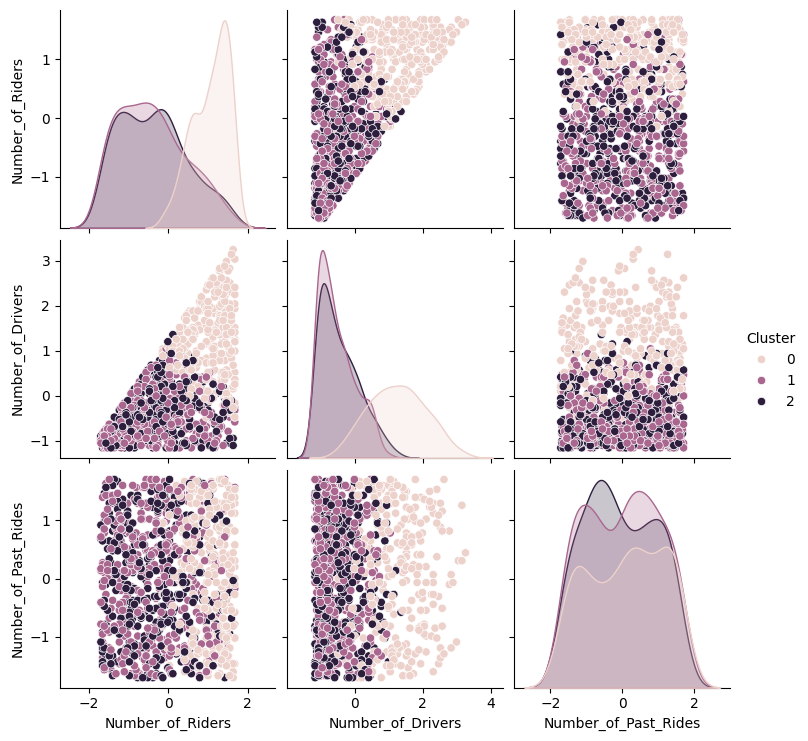

RMSE: 65.61
R2 Score: 0.88
+----+-------------------------+---------------+
|    | Feature                 |   Coefficient |
+====+=========================+===============+
|  0 | Number_of_Riders        |     -1.70286  |
+----+-------------------------+---------------+
|  1 | Number_of_Drivers       |      5.37754  |
+----+-------------------------+---------------+
|  2 | Location_Category       |     -0.938989 |
+----+-------------------------+---------------+
|  3 | Customer_Loyalty_Status |      1.26426  |
+----+-------------------------+---------------+
|  4 | Number_of_Past_Rides    |      1.41989  |
+----+-------------------------+---------------+
|  5 | Average_Ratings         |      2.43581  |
+----+-------------------------+---------------+
|  6 | Time_of_Booking         |     -2.31803  |
+----+-------------------------+---------------+
|  7 | Vehicle_Type            |     45.3326   |
+----+-------------------------+---------------+
|  8 | Expected_Ride_Duration  |    173.43

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
file_path = '/content/drive/MyDrive/SDI/Case Study 3: Dynamic Pricing/dynamic_pricing 1.csv'
df = pd.read_csv(file_path)

# 2. Tabulate Data Information
data_info = []
for col in df.columns:
    data_info.append([
        col,
        df[col].isna().sum(),
        df[col].dtype,
        df[col].nunique(),
        df[col].unique()[:10]
    ])

print(tabulate(data_info, headers=["Column Name", "Missing Values", "Data Type", "Unique Values", "Sample Values"], tablefmt="grid"))
print(f"Number of rows: {len(df)}")

# 3. Preprocessing

# Handle missing values (if any)
df = df.dropna()

# Encode categorical columns
cat_cols = ['Location_Category', 'Customer_Loyalty_Status', 'Time_of_Booking', 'Vehicle_Type']
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

# Normalize numerical features
numerical_cols = [
    'Number_of_Riders', 'Number_of_Drivers', 'Number_of_Past_Rides',
    'Average_Ratings', 'Expected_Ride_Duration'
]
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# 4. Clustering: Segmentasi pelanggan
cluster_features = numerical_cols + cat_cols
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(df[cluster_features])

# Visualisasi Clustering (Opsional)
sns.pairplot(df, hue='Cluster', diag_kind='kde', vars=numerical_cols[:3])
plt.show()

# 5. Linear Regression Model

# Target & Features
X = df.drop(columns=['Historical_Cost_of_Ride'])
y = df['Historical_Cost_of_Ride']

# Train model
lr = LinearRegression()
lr.fit(X, y)

# Predict & Evaluate
y_pred = lr.predict(X)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

# 6. Analisis Koefisien
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr.coef_})
print(tabulate(coef_df, headers='keys', tablefmt='grid'))

In [ ]:
# 7. Tambahkan prediksi dari model regresi
df['Predicted_Cost'] = y_pred

# 8. Strategi markup per cluster
markup_dict = {
    0: 1.05,  # Hemat
    1: 1.10,  # Menengah
    2: 1.15   # Premium
}

# 9. Terapkan dynamic pricing
df['Markup'] = df['Cluster'].map(markup_dict)
df['Dynamic_Price'] = df['Predicted_Cost'] * df['Markup']

# 10. Ringkasan hasil
summary = df[['Historical_Cost_of_Ride', 'Predicted_Cost', 'Dynamic_Price', 'Cluster']].head(10)
print(tabulate(summary, headers='keys', tablefmt='grid'))

+----+---------------------------+------------------+-----------------+-----------+
|    |   Historical_Cost_of_Ride |   Predicted_Cost |   Dynamic_Price |   Cluster |
+====+===========================+==================+=================+===========+
|  0 |                   284.257 |          365.295 |         383.559 |         0 |
+----+---------------------------+------------------+-----------------+-----------+
|  1 |                   173.875 |          150.21  |         172.741 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  2 |                   329.795 |          310.282 |         356.824 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  3 |                   470.201 |          514.535 |         591.716 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  4 |                   579.681 |          518.561 |         596.345 |     

In [ ]:
cluster_price_summary = df.groupby('Cluster')[['Historical_Cost_of_Ride', 'Dynamic_Price']].mean().reset_index()
print(tabulate(cluster_price_summary, headers='keys', tablefmt='grid'))

+----+-----------+---------------------------+-----------------+
|    |   Cluster |   Historical_Cost_of_Ride |   Dynamic_Price |
+====+===========+===========================+=================+
|  0 |         0 |                   372.758 |         391.004 |
+----+-----------+---------------------------+-----------------+
|  1 |         1 |                   372.503 |         410.367 |
+----+-----------+---------------------------+-----------------+
|  2 |         2 |                   372.304 |         427.816 |
+----+-----------+---------------------------+-----------------+


+-------------------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
| Column Name             |   Missing Values | Data Type   |   Unique Values | Sample Values                                                      |
+=========================+==================+=============+=================+====================================================================+
| Number_of_Riders        |                0 | int64       |              81 | [90 58 42 89 78 59 93 62 79 86]                                    |
+-------------------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
| Number_of_Drivers       |                0 | int64       |              79 | [45 39 31 28 22 35 43 14  6 17]                                    |
+-------------------------+------------------+-------------+-----------------+----------------------------------

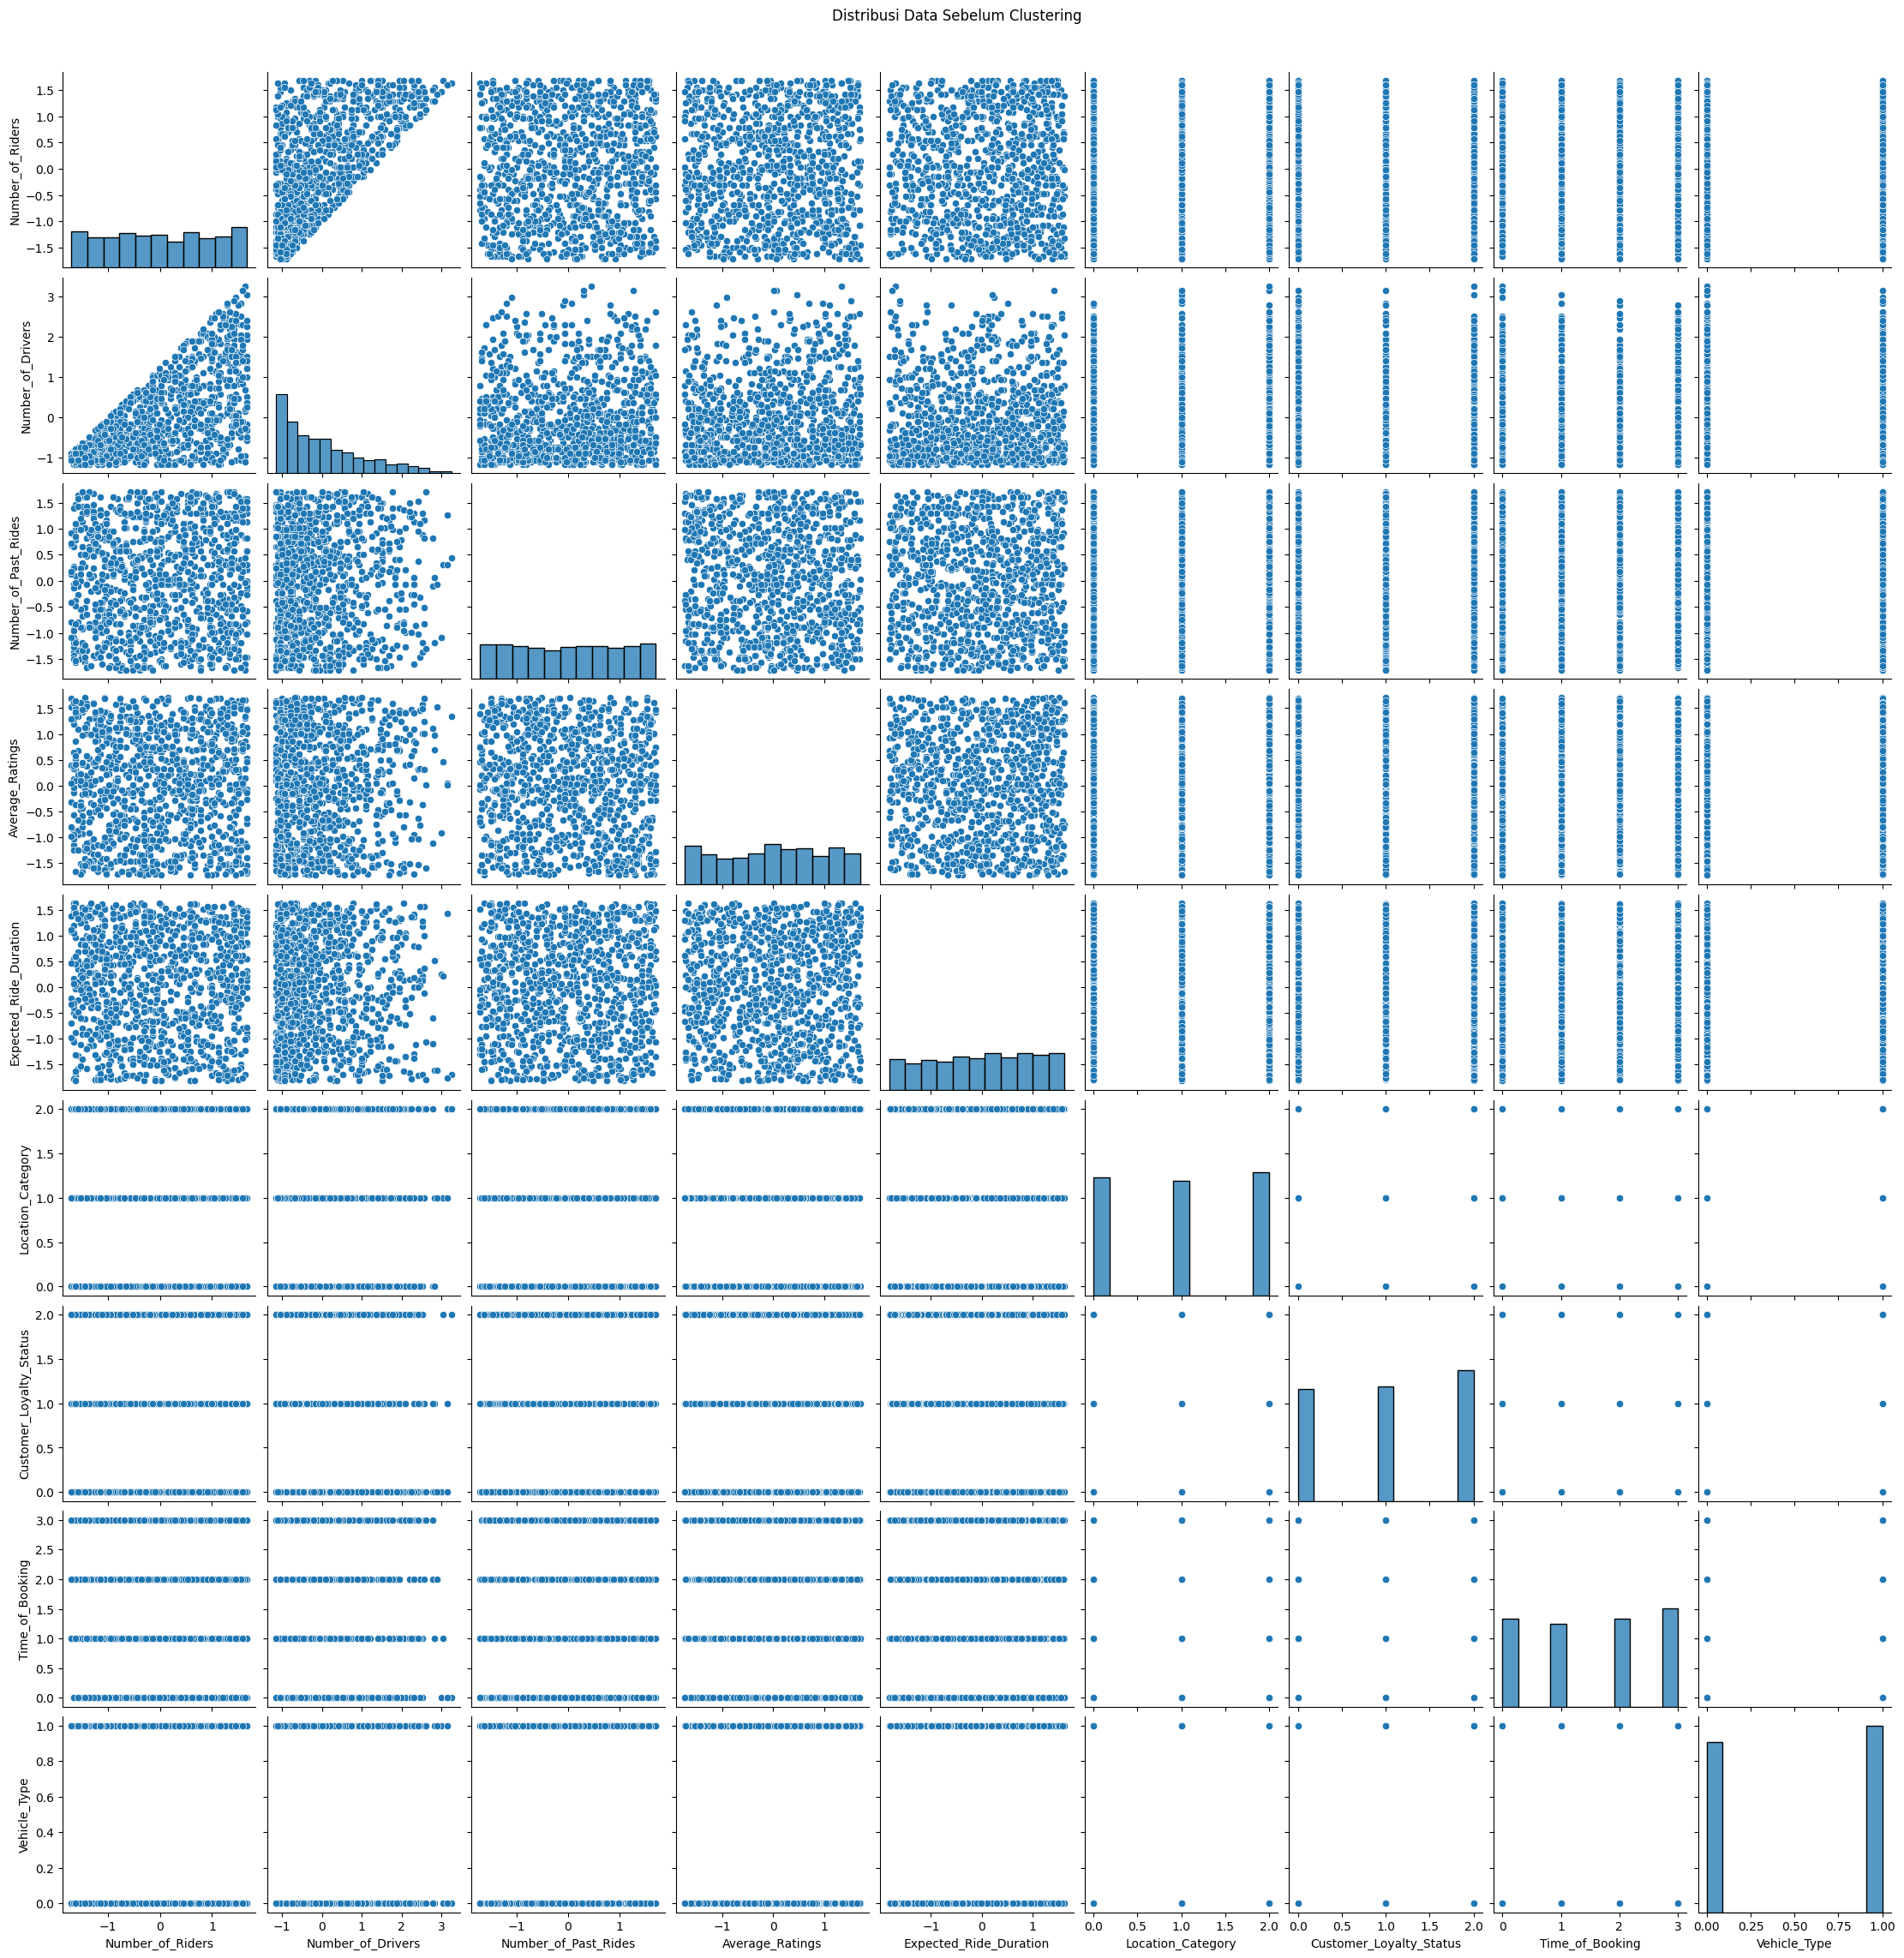

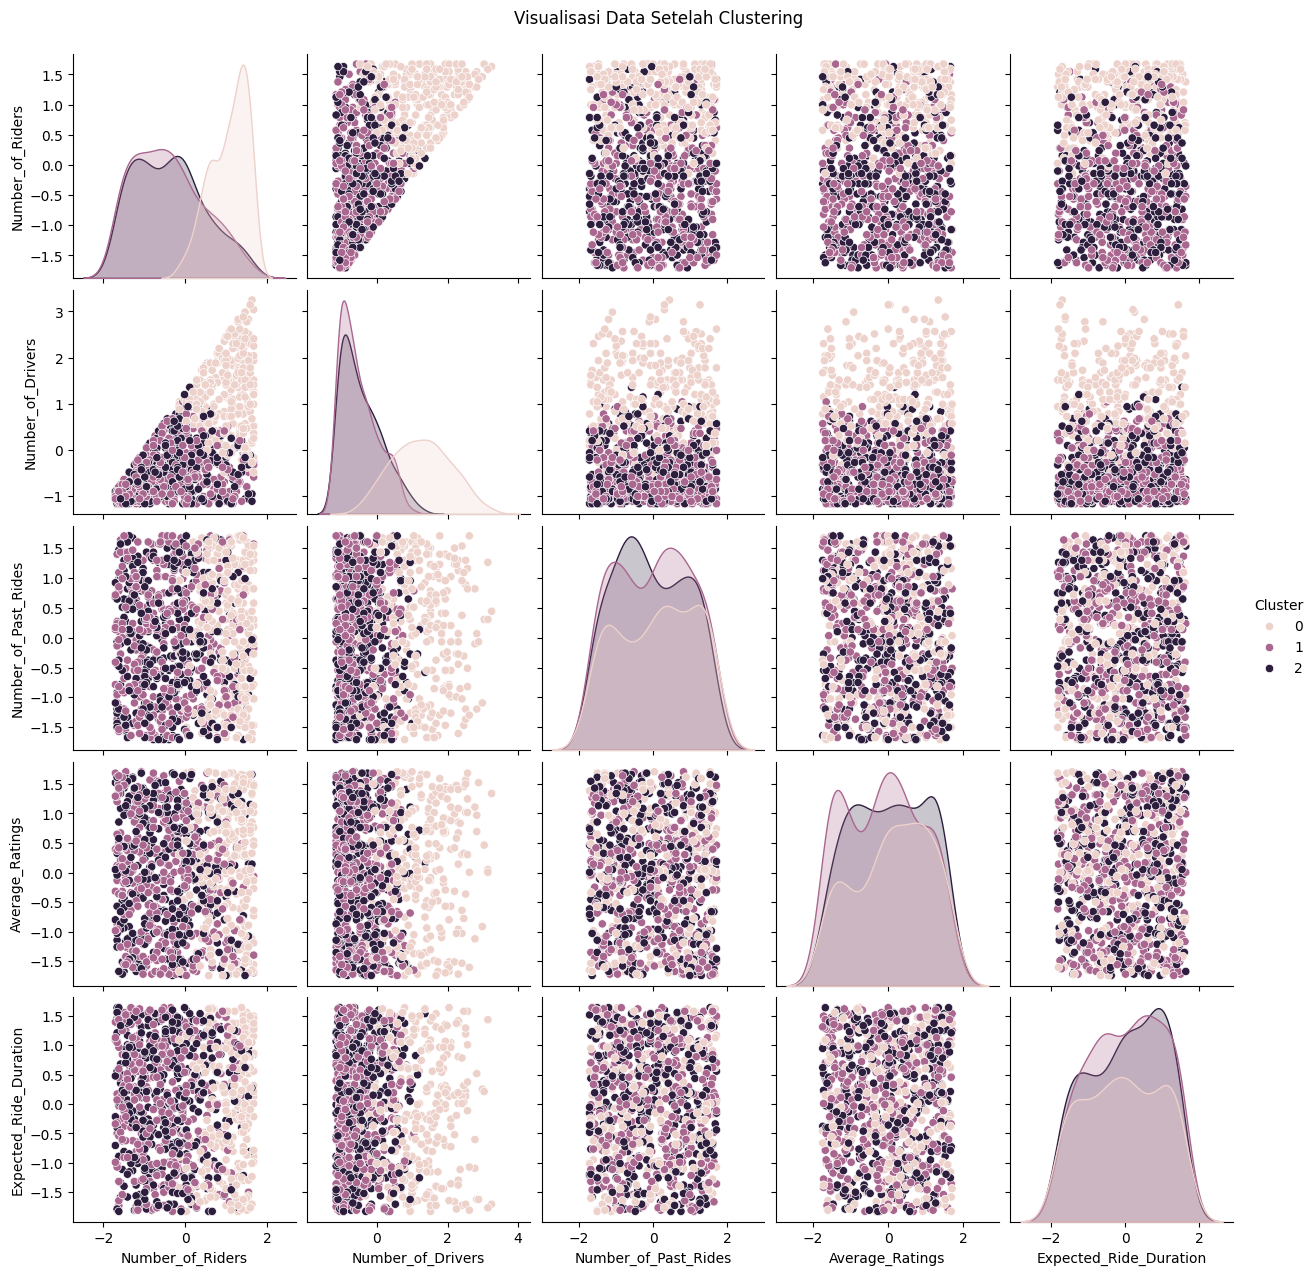

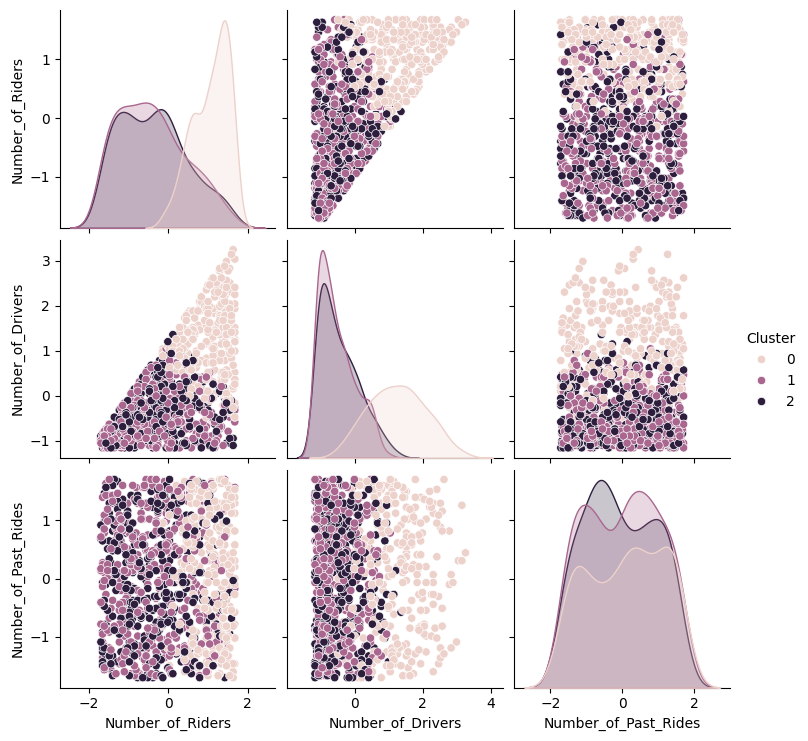

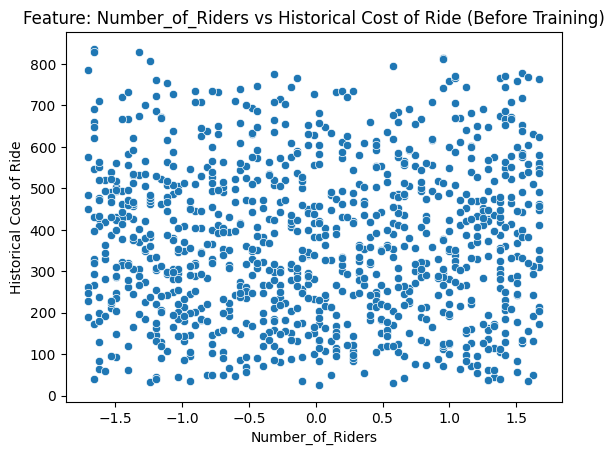

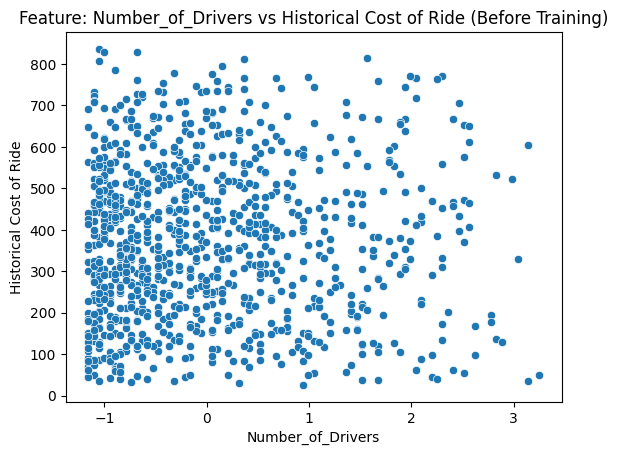

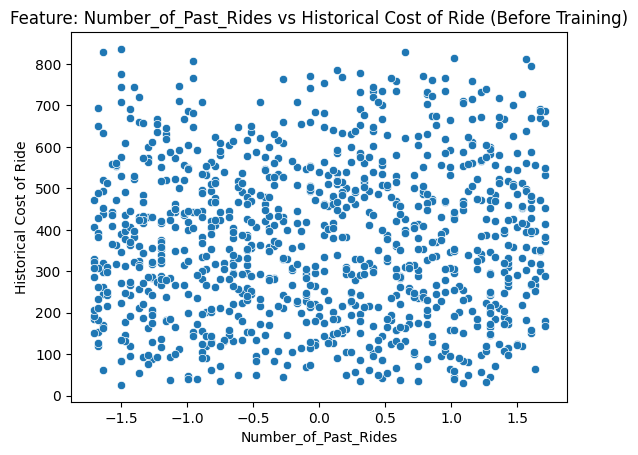

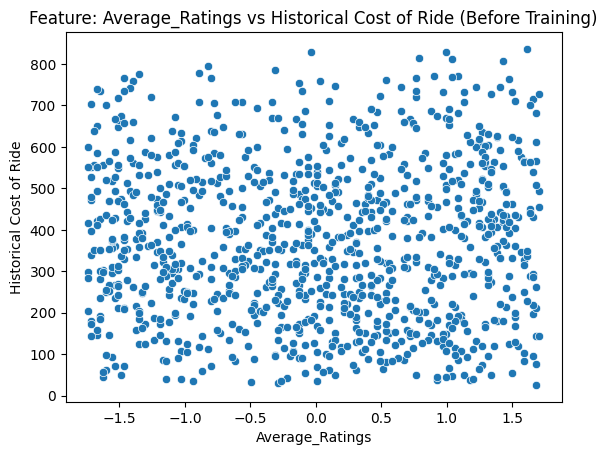

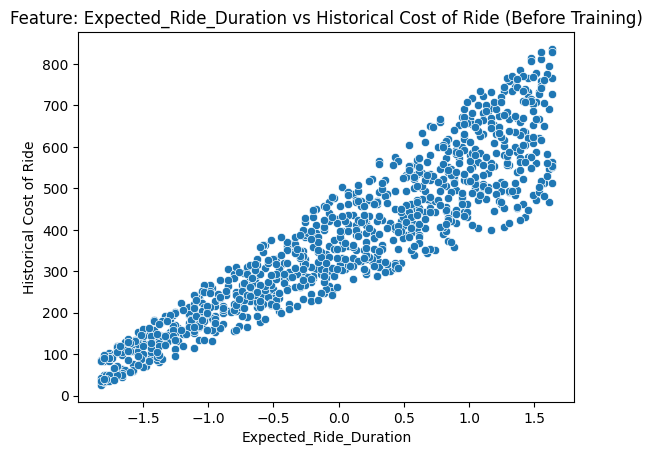

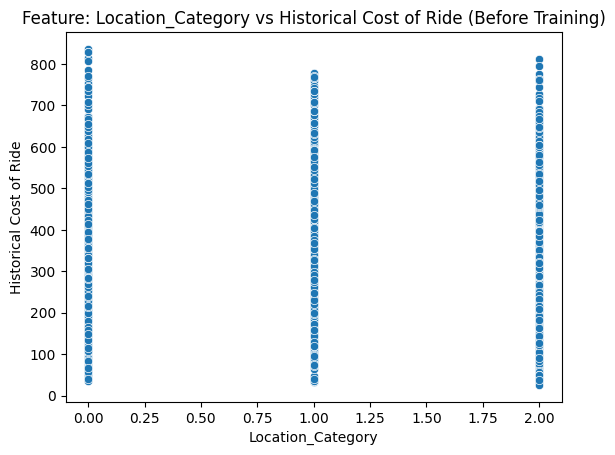

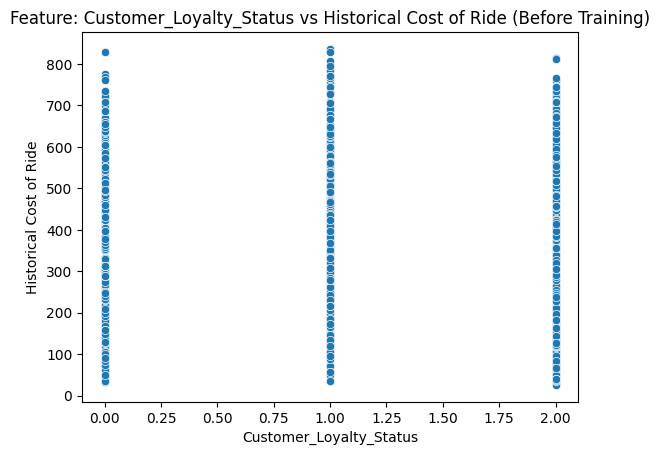

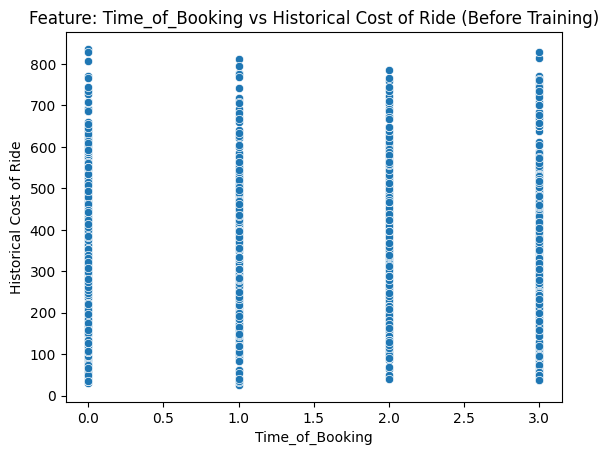

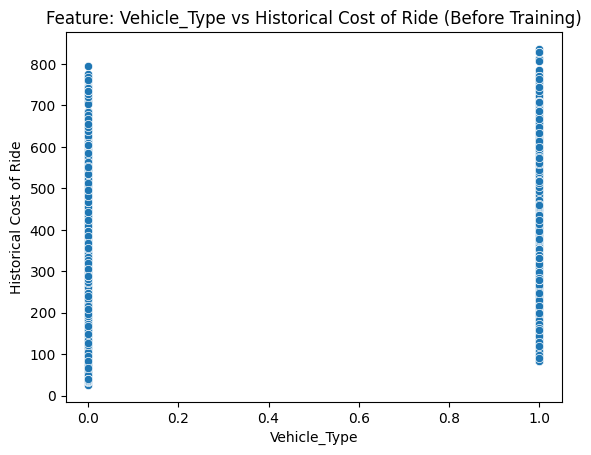

[2 Fitur] RMSE: 0.00
[2 Fitur] R2 Score: 1.00


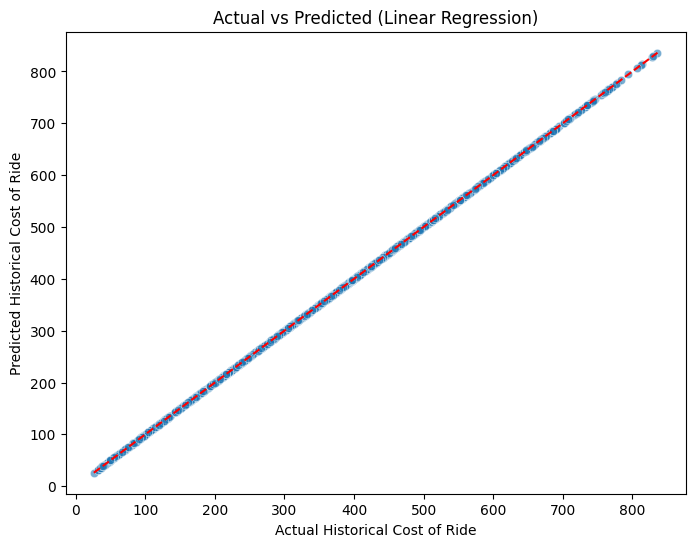

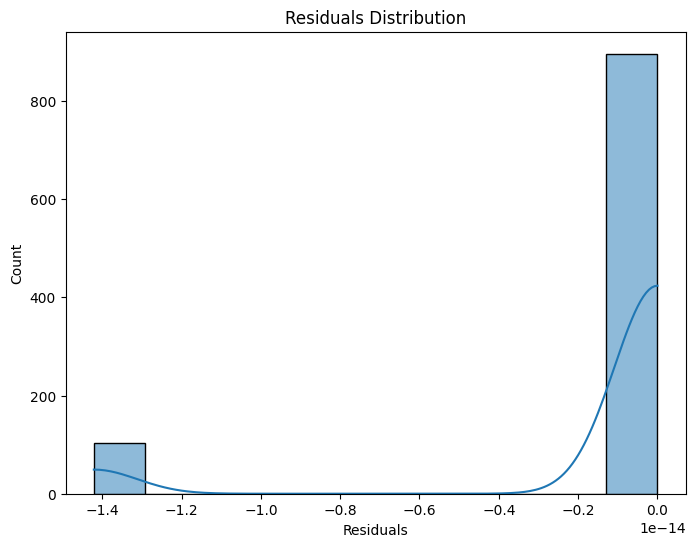

+----+-------------------------+---------------+
|    | Feature                 |   Coefficient |
+====+=========================+===============+
|  0 | Expected_Ride_Duration  |  -8.38313e-15 |
+----+-------------------------+---------------+
|  1 | Historical_Cost_of_Ride |   1           |
+----+-------------------------+---------------+


NameError: name 'X' is not defined

In [ ]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
file_path = '/content/drive/MyDrive/SDI/Case Study 3: Dynamic Pricing/dynamic_pricing 1.csv'
df = pd.read_csv(file_path)

# 2. Tabulate Data Information
data_info = []
for col in df.columns:
    data_info.append([
        col,
        df[col].isna().sum(),
        df[col].dtype,
        df[col].nunique(),
        df[col].unique()[:10]
    ])

print(tabulate(data_info, headers=["Column Name", "Missing Values", "Data Type", "Unique Values", "Sample Values"], tablefmt="grid"))
print(f"Number of rows: {len(df)}")

# 3. Preprocessing
df = df.dropna()

# Encode categorical columns
cat_cols = ['Location_Category', 'Customer_Loyalty_Status', 'Time_of_Booking', 'Vehicle_Type']
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

# Normalize numerical features
numerical_cols = [
    'Number_of_Riders', 'Number_of_Drivers', 'Number_of_Past_Rides',
    'Average_Ratings', 'Expected_Ride_Duration'
]
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# -------------------------------
# Clustering: Sebelum Clustering
# -------------------------------
# Sebelum Clustering - Pairplot untuk melihat distribusi data awal
cluster_features = numerical_cols + cat_cols
sns.pairplot(df[cluster_features])
plt.suptitle('Distribusi Data Sebelum Clustering', y=1.02)
plt.show()

# 4. Clustering: Segmentasi pelanggan
cluster_features = numerical_cols + cat_cols
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(df[cluster_features])

# -------------------------------
# Clustering: Setelah Clustering
# -------------------------------
sns.pairplot(df, hue='Cluster', diag_kind='kde', vars=numerical_cols)
plt.suptitle('Visualisasi Data Setelah Clustering', y=1.02)
plt.show()

# Visualisasi Pairplot Clustering
sns.pairplot(df, hue='Cluster', diag_kind='kde', vars=numerical_cols[:3])
plt.show()

y = df['Historical_Cost_of_Ride']

for col in numerical_cols + cat_cols:
    sns.scatterplot(x=df[col], y=y)
    plt.title(f'Feature: {col} vs Historical Cost of Ride (Before Training)')
    plt.xlabel(col)
    plt.ylabel('Historical Cost of Ride')
    plt.show()

# 5. Linear Regression Model (2 fitur terkuat)
selected_features = ['Expected_Ride_Duration', 'Historical_Cost_of_Ride']

X_selected = df[selected_features]
y = df['Historical_Cost_of_Ride']

# Train model dengan 2 fitur
lr_selected = LinearRegression()
lr_selected.fit(X_selected, y)

# Predict & Evaluate
y_pred_selected = lr_selected.predict(X_selected)
rmse_selected = np.sqrt(mean_squared_error(y, y_pred_selected))
r2_selected = r2_score(y, y_pred_selected)

print(f"[2 Fitur] RMSE: {rmse_selected:.2f}")
print(f"[2 Fitur] R2 Score: {r2_selected:.2f}")

# Setelah Training - Plot y_actual vs y_predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y, y=y_pred_selected, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # Garis 45 derajat
plt.xlabel('Actual Historical Cost of Ride')
plt.ylabel('Predicted Historical Cost of Ride')
plt.title('Actual vs Predicted (Linear Regression)')
plt.show()

# Residual Plot
residuals = y - y_pred_selected
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True)
plt.title('Residuals Distribution')
plt.xlabel('Residuals')
plt.show()

# Koefisien model (2 fitur)
coef_selected_df = pd.DataFrame({'Feature': selected_features, 'Coefficient': lr_selected.coef_})
print(tabulate(coef_selected_df, headers='keys', tablefmt='grid'))


# 6. Analisis Koefisien
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr.coef_})
print(tabulate(coef_df, headers='keys', tablefmt='grid'))

+----+---------------------------+------------------+-----------------+-----------+
|    |   Historical_Cost_of_Ride |   Predicted_Cost |   Dynamic_Price |   Cluster |
+====+===========================+==================+=================+===========+
|  0 |                   284.257 |          365.295 |         383.559 |         0 |
+----+---------------------------+------------------+-----------------+-----------+
|  1 |                   173.875 |          150.21  |         172.741 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  2 |                   329.795 |          310.282 |         356.824 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  3 |                   470.201 |          514.535 |         591.716 |         2 |
+----+---------------------------+------------------+-----------------+-----------+
|  4 |                   579.681 |          518.561 |         596.345 |     

<ipython-input-252-db20755bed75>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df.sort_values(by='Coefficient', ascending=False),


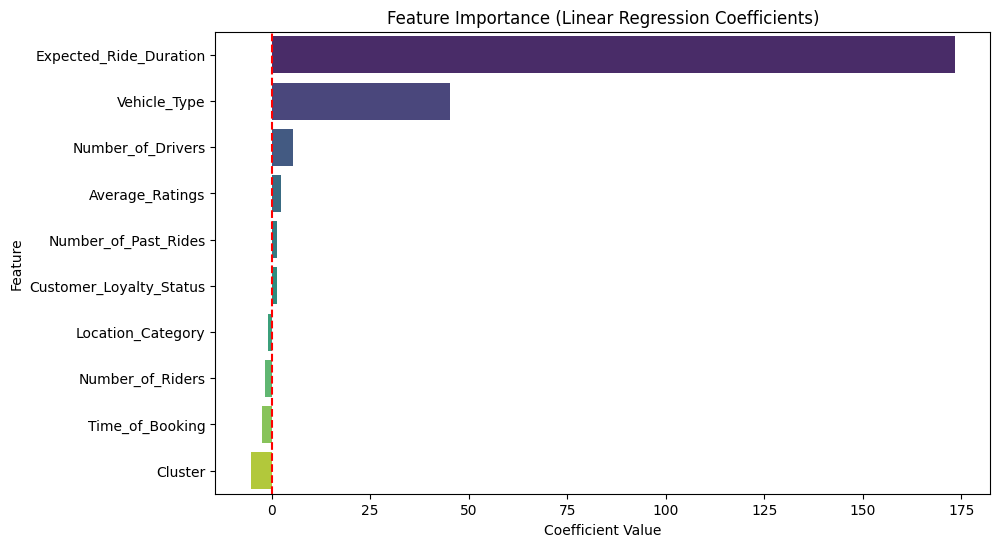

In [ ]:

# 7. Tambahkan prediksi dari model regresi
df['Predicted_Cost'] = y_pred

# 8. Strategi markup per cluster
markup_dict = {
    0: 1.05,  # Hemat
    1: 1.10,  # Menengah
    2: 1.15   # Premium
}

# 9. Terapkan dynamic pricing
df['Markup'] = df['Cluster'].map(markup_dict)
df['Dynamic_Price'] = df['Predicted_Cost'] * df['Markup']

# 10. Ringkasan hasil
summary = df[['Historical_Cost_of_Ride', 'Predicted_Cost', 'Dynamic_Price', 'Cluster']].head(10)
print(tabulate(summary, headers='keys', tablefmt='grid'))

# -----------------------------------------------
# Visualisasi: Feature Importance (Koefisien Regresi)
# -----------------------------------------------
plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df.sort_values(by='Coefficient', ascending=False),
            x='Coefficient', y='Feature', palette='viridis')
plt.title('Feature Importance (Linear Regression Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.axvline(0, color='red', linestyle='--')
plt.show()

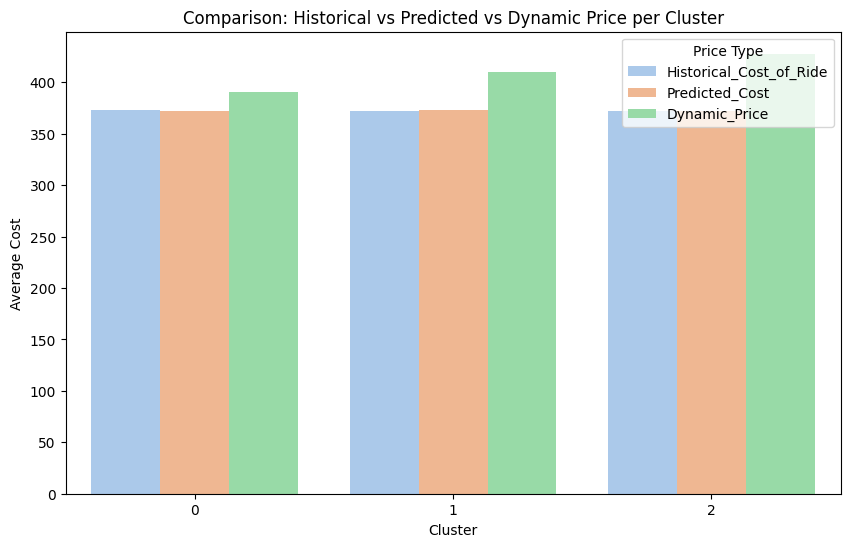

In [ ]:

# Ringkasan data rata-rata per cluster
cluster_summary = df.groupby('Cluster')[['Historical_Cost_of_Ride', 'Predicted_Cost', 'Dynamic_Price']].mean().reset_index()

# Melt data agar bisa di-plot dengan seaborn
cluster_melted = cluster_summary.melt(id_vars='Cluster',
                                      value_vars=['Historical_Cost_of_Ride', 'Predicted_Cost', 'Dynamic_Price'],
                                      var_name='Price_Type', value_name='Average_Cost')

# Visualisasi Grouped Barplot
plt.figure(figsize=(10, 6))
sns.barplot(data=cluster_melted, x='Cluster', y='Average_Cost', hue='Price_Type', palette='pastel')
plt.title('Comparison: Historical vs Predicted vs Dynamic Price per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Cost')
plt.legend(title='Price Type')
plt.show()

YANG INI YANG DIAPAKAi

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import silhouette_score


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load data
file_path = '/content/drive/MyDrive/SDI/Case Study 3: Dynamic Pricing/dynamic_pricing 1.csv'
df = pd.read_csv(file_path)

PReprocessing

In [ ]:
# Tentukan fitur dan target
X = df.drop(columns=["Historical_Cost_of_Ride"])
y = df["Historical_Cost_of_Ride"]

# Preprocessing: Pisahkan fitur numerik dan kategorikal
numerical_features = ["Number_of_Riders", "Number_of_Drivers", "Number_of_Past_Rides",
                      "Average_Ratings", "Expected_Ride_Duration"]
categorical_features = ["Location_Category", "Customer_Loyalty_Status",
                        "Time_of_Booking", "Vehicle_Type"]

# Preprocessing pipelines
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first')  # Hindari dummy variable trap
# select only numeric columns
correlation_matrix = df.select_dtypes(include=[np.number].corr)

# Tampilkan matriks korelasi
print("\nMatriks Korelasi untuk Kolom Numerik:")
print(tabulate(correlation_matrix, headers='keys', tablefmt='grid'))

# Opsional: Visualisasi matriks korelasi menggunakan heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap Matriks Korelasi Fitur Numerik')
plt.show()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)


AttributeError: 'list' object has no attribute 'corr'

AttributeError: 'list' object has no attribute 'corr'

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SDI/Case Study 3: Dynamic Pricing/dynamic_pricing 1.csv'

In [ ]:
# Linear Regression
X = df.drop('Historical_Cost_of_Ride', axis=1)
y = df['Historical_Cost_of_Ride']

# === 5. Train-test split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === 4. Buat pipeline regresi linear ===
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# === 6. Train model ===
model.fit(X_train, y_train)


In [ ]:
# === 7. Prediksi dan evaluasi ===
y_pred = model.predict(X_test)

print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

# === 8. Visualisasi Hasil Prediksi ===
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Line y=x
plt.xlabel("Actual Cost")
plt.ylabel("Predicted Cost")
plt.title("Actual vs Predicted Ride Cost")
plt.show()

In [ ]:
# === 9. Analisis Koefisien ===

# Ambil nama-nama fitur setelah preprocessing (numerik + one-hot encoded)
feature_names_num = numerical_features
feature_names_cat = model.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([feature_names_num, feature_names_cat])

# Ambil koefisien dari model regresi
coefficients = model.named_steps["regressor"].coef_

# Buat DataFrame untuk analisis
coef_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient": coefficients
}).sort_values(by="Coefficient", key=abs, ascending=False)

# Tampilkan tabel
print(coef_df)

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", palette="coolwarm")
plt.title("Feature Importance (Linear Regression Coefficients)")
plt.axvline(0, color='black', linestyle='--')
plt.tight_layout()
plt.show()
